# 01 — Real parking-data audit

**Project 52: Smart Parking Occupancy and Vehicle Flow Predictor**

This is a working Python/Jupyter data notebook, not a trained forecasting model.
It uses genuine Birmingham occupancy records downloaded from the [UCI publisher page](https://archive.ics.uci.edu/dataset/482/parking+birmingham).
Source ID: `SRC-DS-003`. No timestamps or observations are synthesized.

We will verify source bytes, quarantine invalid/duplicate records, and split whole dates chronologically.

## Why a separate test period?

**Everyday explanation:** learn from earlier days, choose settings on later practice days, and keep the final days for the final exam.

**Technical explanation:** time-ordered holdouts reduce future-to-past leakage. Every car park observed on a particular date goes into the same split. Data-dependent normalization must later be fitted on training records alone.

This audit inspects data quality and coverage, not predictive test performance. No model has seen the test labels for optimization.

In [1]:
from pathlib import Path
import json
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((path for path in candidates if (path / 'configs/birmingham_split.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the project folder.')
sys.path.insert(0, str(ROOT / 'src'))
from smart_parking.data import acquire, prepare, sha256
print('Python:', sys.version.split()[0])
print('Project:', ROOT)


Python: 3.12.10
Project: D:\deep learning\project001


In [2]:
raw_path = acquire(ROOT, allow_download=False)
print('Verified raw file:', raw_path.name)
print('SHA-256:', sha256(raw_path))
print('Offline acquisition check passed; no network request was made.')


Verified raw file: dataset.csv
SHA-256: F1E28B9C697769A1A05CD20148241B60B1A73FEE4907611163EFC6FD9D12770A
Offline acquisition check passed; no network request was made.


## Preserve mistakes instead of hiding them

Occupancy must be an integer between zero and capacity. An observed value above capacity is quarantined, not clipped into a plausible label. Identical repeated observations keep their original row references; extra copies go to quarantine. Conflicting values for one car park and timestamp would all be quarantined.

The file's `Occupancy` field is treated as a count for this preparation protocol. UCI calls it a rate in some descriptions; retain that terminology discrepancy and validate interpretation before scientific modelling.

In [3]:
report = prepare(ROOT)
for key in ['raw_rows', 'accepted_rows', 'quarantine_rows', 'invalid_rows',
            'identical_duplicate_rows_removed', 'conflicting_duplicate_groups',
            'car_parks', 'capture_days']:
    print(f'{key}: {report[key]}')
assert report['accepted_rows'] + report['quarantine_rows'] == report['raw_rows']
print('Row conservation: PASS')


raw_rows: 35717
accepted_rows: 35116
quarantine_rows: 601
invalid_rows: 385
identical_duplicate_rows_removed: 216
conflicting_duplicate_groups: 0
car_parks: 30
capture_days: 73
Row conservation: PASS


In [4]:
for split in report['splits']:
    print(f"{split['split']:10s}: {split['rows']:5d} records, {split['days']:2d} days | "
          f"{split['first_timestamp']} to {split['last_timestamp']}")
assert report['splits'][0]['last_timestamp'] < report['splits'][1]['first_timestamp']
assert report['splits'][1]['last_timestamp'] < report['splits'][2]['first_timestamp']
print('Strict chronological boundaries: PASS')


train     : 24689 records, 51 days | 2016-10-04 07:46:28 to 2016-11-25 16:27:58
validation:  4795 records, 10 days | 2016-11-26 07:55:00 to 2016-12-07 16:32:23
test      :  5632 records, 12 days | 2016-12-08 07:32:25 to 2016-12-19 16:30:35
Strict chronological boundaries: PASS


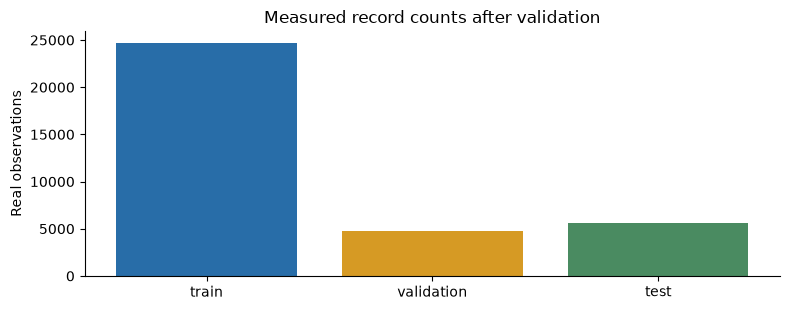

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar([s['split'] for s in report['splits']], [s['rows'] for s in report['splits']],
       color=['#286DA8', '#D69A24', '#4A8B61'])
ax.set(title='Measured record counts after validation', ylabel='Real observations')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()


## What is still unverified?

- Original timestamps have no explicit timezone offset; no UTC conversion is invented.
- Observations are irregular and contain overnight/long gaps. No LSTM windows are generated here.
- Some entity names may represent overlapping physical parking areas. Never sum them into one capacity.
- Some car parks lack a later validation/test period. See the coverage report.
- This dataset has no images, vehicle boxes or segmentation masks. It cannot train those tasks.
- No forecast accuracy, MAE, classifier accuracy or FPS has been measured.

Source provenance and licensing caveats are in `docs/DATASET_PROVENANCE.md` and `docs/LICENSING_RECORD.md`.

## Your practice task

1. Explain why shuffling these records randomly would be a poor forecasting split.
2. Find one car park with no test records in `report['car_park_coverage']`.
3. Explain why we cannot call this notebook a trained LSTM.

Try before asking for the answers. Mastery remains unassessed.